> **VERSÃO GABARITO** — todas as células preenchidas. Use esta para projetar; distribua a outra para a turma.

# Posição e dispersão com Python

**Pergunta da aula:** um filme de terror típico existe?

Você já sabe média, mediana, desvio padrão e quartis — a teoria não é
novidade. O que é novo é **extrair e plotar** essas medidas em Python. E,
no caminho, uma coisa que costuma passar batido na aula de estatística:
o resumo depende de **quem entrou na conta**.

**Dados:** 32.540 filmes de terror do TMDB, com nota, número de votos,
duração, orçamento e bilheteria.
Fonte: [TidyTuesday, 2022-11-01](https://github.com/rfordatascience/tidytuesday/tree/main/data/2022/2022-11-01).

---

### Como usar este notebook

Um notebook é uma sequência de **células**. Célula de texto (como esta) e
célula de código. Para rodar uma célula de código: clique nela e aperte
**Shift + Enter**.

Quando aparecer **SUA VEZ**, a célula é sua: ou está vazia e o código está
no texto acima, ou tem lacunas `____` para preencher.

Se algo quebrar, leia a **última linha** da mensagem de erro. É lá que
está a informação útil.

---

## 0 · Preparando o ambiente  `⏱️ 0–8 min`

Em R você carrega pacotes com `library()`. Em Python é `import`.
O `as pd` cria um apelido: em vez de escrever `pandas` toda vez, escreve `pd`.

Os três pacotes de hoje são os mesmos das aulas anteriores:

- **pandas** — tabelas. É o `data.frame` do Python.
- **seaborn** — gráficos estatísticos.
- **matplotlib** — o motor gráfico por baixo do seaborn.

A célula abaixo **instala** (se faltar) e **carrega** os três.
No Colab, rode **uma vez** no começo da aula — não precisa instalar nada à mão.

In [1]:
# Instala o que faltar e carrega os pacotes da aula (Colab e Jupyter).
# Rode esta célula uma vez no começo.
%pip install -q pandas seaborn matplotlib

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

print("pandas", pd.__version__)
print("seaborn", sns.__version__)
print("Pronto — ambiente ok.")

/Users/caio.nunes/Projects/lab-exploratory-data-analysis/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.
pandas 3.0.6
seaborn 0.13.2
Pronto — ambiente ok.


---

## 1 · Warmup: o mesmo começo de sempre  `⏱️ 8–20 min`

Antes de medir qualquer coisa: abrir a tabela e olhar. Nada nesta seção
é novo — são os mesmos verbos da aula 2, de propósito. É para você
retomar o ritmo antes de aprender medida nova.

`read_csv` lê direto da URL, sem download manual.

In [2]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2022/2022-11-01/horror_movies.csv"

filmes = pd.read_csv(URL)

print("Carregado.")

Carregado.


### SUA VEZ — digite você mesmo

`head()` mostra as primeiras linhas da tabela.

```python
filmes.head()
```

In [3]:
filmes.head()

,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,760161,Orphan: First Kill,Orphan: First Kill,en,After escaping from an Estonian psychiatric fa...,There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,5088.584,902,6.9,0,9572765,99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller",760193.0,Orphan Collection
1,760741,Beast,Beast,en,A recently widowed man and his two teenage dau...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,2172.338,584,7.1,0,56000000,93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,1863.628,114,6.8,17000000,45000000,115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,1071.398,2736,7.9,18800000,161000000,103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,772450,Presencias,Presences,es,A man who loses his wife and goes to seclude h...,NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,1020.995,83,7.0,0,0,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


In [4]:
colunas = filmes.columns.tolist()

print("linhas, colunas:", filmes.shape)
print()
print(colunas)

linhas, colunas: (32540, 20)

['id', 'original_title', 'title', 'original_language', 'overview', 'tagline', 'release_date', 'poster_path', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue', 'runtime', 'status', 'adult', 'backdrop_path', 'genre_names', 'collection', 'collection_name']


`shape` devolve (linhas, colunas) — é o `dim()` do R, e aqui **sem**
parênteses: `shape` é atributo, não função. `columns` lista os nomes.

In [5]:
filmes.info()

<class 'pandas.DataFrame'>
RangeIndex: 32540 entries, 0 to 32539
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 32540 non-null  int64  
 1   original_title     32540 non-null  str    
 2   title              32540 non-null  str    
 3   original_language  32540 non-null  str    
 4   overview           31254 non-null  str    
 5   tagline            12706 non-null  str    
 6   release_date       32540 non-null  str    
 7   poster_path        28066 non-null  str    
 8   popularity         32540 non-null  float64
 9   vote_count         32540 non-null  int64  
 10  vote_average       32540 non-null  float64
 11  budget             32540 non-null  int64  
 12  revenue            32540 non-null  int64  
 13  runtime            32540 non-null  int64  
 14  status             32540 non-null  str    
 15  adult              32540 non-null  bool   
 16  backdrop_path      13545 non-null

### O dicionário das variáveis

São vinte colunas, mas hoje usamos seis:

| coluna | o que é |
|---|---|
| `title`, `release_date` | nome e data de lançamento |
| `vote_average` | nota média, de 0 a 10 |
| `vote_count` | quantas pessoas deram nota |
| `runtime` | duração em minutos |
| `budget` | orçamento em dólares |
| `revenue` | bilheteria em dólares |

Repare que a nota vem sempre **acompanhada** da contagem. Uma nota 9,5
com dois votos não é a mesma informação que uma nota 9,5 com dez mil.
Esse par volta na seção 5 e é o que resolve a aula.

### O resumo de uma variável

`describe()` devolve as medidas de posição e dispersão de uma vez:
contagem, média, desvio padrão, mínimo, os três quartis e o máximo.
É o `summary()` do R.

Já vamos usá-lo — mas repare em três linhas dele.

In [6]:
filmes[["vote_average", "runtime", "vote_count", "revenue"]].describe()

,vote_average,runtime,vote_count,revenue
count,32540.000000,32540.000000,32540.000000,3.254000e+04
mean,3.335728,62.142901,62.691487,1.349747e+06
std,2.876002,40.998527,420.887474,1.443048e+07
min,0.000000,0.000000,0.000000,0.000000e+00
25%,0.000000,14.000000,0.000000,0.000000e+00
50%,4.000000,80.000000,2.000000,0.000000e+00
75%,5.700000,91.000000,11.000000,0.000000e+00
max,10.000000,683.000000,16900.000000,7.018426e+08


`vote_average` tem média **3,34** e mediana **4,00**, com o primeiro
quartil em **0,00**. Um quarto dos filmes da tabela tem nota zero.

Nota zero aqui não é filme ruim: é filme que ninguém avaliou.

`vote_count` repete o padrão no outro extremo: média **62,69** e mediana
**2,00**. E `revenue` tem mediana **0,00** com média de 1,3 milhão,
porque a maioria dos filmes não tem bilheteria registrada na base.

Nos três casos o `describe()` está certo e a leitura ingênua está errada.
É sobre isso a aula inteira.

### SUA VEZ — troque a coluna

Rode o `describe()` de novo trocando a lista por uma coluna que ainda não
olhamos: `budget`, `popularity` ou `runtime`.

```python
filmes["budget"].describe()
```

In [7]:
filmes["budget"].describe()

count    3.254000e+04
mean     5.431266e+05
std      4.542668e+06
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.000000e+08
Name: budget, dtype: float64

---

## 2 · Quem entra na conta  `⏱️ 20–32 min`

A tabela tem 32.540 linhas, mas **linha** é uma unidade de observação que
a gente assume sem verificar. Na aula 2 descobrimos que a linha era
música-em-playlist, não música. Aqui tem outra coisa.

Antes, precisamos do ano de lançamento — que na tabela está dentro de um
texto, não numa coluna numérica.

In [8]:
# release_date vem como texto ("1999-08-06"). to_datetime converte.
# errors="coerce" transforma o que nao for data em valor ausente,
# em vez de quebrar o notebook.
filmes["ano"] = pd.to_datetime(filmes["release_date"], errors="coerce").dt.year

sem_data = filmes["ano"].isna().sum()
mais_antigo = filmes["ano"].min()
mais_recente = filmes["ano"].max()

print("filmes sem data legivel:", sem_data)
print("mais antigo:", mais_antigo, "| mais recente:", mais_recente)

filmes sem data legivel: 0
mais antigo: 1950 | mais recente: 2022


Agora, a contagem que muda a aula: quantos filmes da tabela **não** têm a
informação que a gente quer medir.

In [9]:
n_filmes = len(filmes)
n_sem_nota = (filmes["vote_count"] == 0).sum()
n_menos_de_10 = (filmes["vote_count"] < 10).sum()
n_duracao_zero = (filmes["runtime"] == 0).sum()
n_curtas = (filmes["runtime"] <= 40).sum()
n_com_bilheteria = (filmes["revenue"] > 0).sum()
n_antes_1970 = (filmes["ano"] < 1970).sum()

print("filmes na tabela:              ", n_filmes)
print()
print("sem nenhuma nota (0 votos):    ", n_sem_nota)
print("com menos de 10 votos:         ", n_menos_de_10)
print("duração zerada:                ", n_duracao_zero)
print("duração até 40 min (curtas):   ", n_curtas)
print("com bilheteria registrada:     ", n_com_bilheteria)
print("lançados antes de 1970:        ", n_antes_1970)

filmes na tabela:               32540

sem nenhuma nota (0 votos):     11602
com menos de 10 votos:          24063
duração zerada:                 2668
duração até 40 min (curtas):    10896
com bilheteria registrada:      1576
lançados antes de 1970:         1109


### SUA VEZ — preencha as lacunas

`n_menos_de_10` é a contagem que você acabou de ver. Divida pelo total
(`n_filmes`) e multiplique por 100 para virar proporção.

```python
proporcao = round(100 * n_menos_de_10 / n_filmes, 1)

print("com menos de 10 votos:", n_menos_de_10)
print("proporção:", proporcao, "%")
```

In [10]:
proporcao = round(100 * n_menos_de_10 / n_filmes, 1)

print("com menos de 10 votos:", n_menos_de_10)
print("proporção:", proporcao, "%")

com menos de 10 votos: 24063
proporção: 73.9 %


**74%.** Três em cada quatro filmes da tabela quase não têm avaliação.

E 11.602 deles têm exatamente zero votos — 11.590 com nota zero também. Se
você calcular a média de `vote_average` sem olhar isso, o resultado é uma
média de notas de filmes que não têm nota.

Não existe "a" tabela deste dataset. Existem recortes, e cada um responde
uma pergunta diferente. Vamos nomear três:

- **`terror`** — filmes de 1970 a 2022. O retrato geral, com os problemas
  à vista.
- **`terror_votado`** — só os que têm 50 votos ou mais. Onde dá para
  falar de nota sem que o ruído domine.
- **`terror_bilheteria`** — só os que têm bilheteria registrada. Onde dá
  para falar de dinheiro.

In [11]:
terror = filmes[filmes["ano"].between(1970, 2022)].copy()
terror["decada"] = (terror["ano"] // 10 * 10).astype(int)

terror_votado = terror[terror["vote_count"] >= 50].copy()
terror_bilheteria = terror[terror["revenue"] > 0].copy()

n_terror = len(terror)
n_votado = len(terror_votado)
n_bilheteria = len(terror_bilheteria)

print("terror:           ", n_terror)
print("terror_votado:    ", n_votado)
print("terror_bilheteria:", n_bilheteria)

terror:            31431
terror_votado:     3307
terror_bilheteria: 1532


`//` é a divisão inteira: `1997 // 10` dá `199`, e `* 10` devolve `1990`.
É como a gente transforma ano em década.

Repare no tamanho dos três: **31.431**, **3.307** e **1.532**. O mesmo
dataset, três populações diferentes. Daqui para a frente, todo número que
aparecer vai dizer de qual delas veio — e quando não disser, desconfie.

Uma última conferência, para ver o tamanho do estrago:

In [12]:
media_terror = round(terror["vote_average"].mean(), 2)
media_votado = round(terror_votado["vote_average"].mean(), 2)
mediana_terror = terror["vote_average"].median()
mediana_votado = terror_votado["vote_average"].median()

print("nota média em terror:        ", media_terror)
print("nota média em terror_votado: ", media_votado)
print()
print("mediana em terror:           ", mediana_terror)
print("mediana em terror_votado:    ", mediana_votado)

nota média em terror:         3.3
nota média em terror_votado:  5.78

mediana em terror:            4.0
mediana em terror_votado:     5.8


A mesma variável, no mesmo dataset: **3,30** de média num recorte e
**5,78** no outro. A diferença inteira é a decisão de quem entra na conta.

---

## 3 · Posição: existe um filme de terror típico?  `⏱️ 32–52 min`

Medidas de posição resumem **onde** os dados estão. Você já sabe o que
são; o que muda é o verbo.

| medida | Python | equivalente em R |
|---|---|---|
| média | `serie.mean()` | `mean()` |
| mediana | `serie.median()` | `median()` |
| quartis e percentis | `serie.quantile([.25, .5, .75])` | `quantile()` |

Comece pela variável mais desconfiada da tabela: quantas pessoas
avaliaram cada filme.

In [13]:
media_votos = round(terror["vote_count"].mean(), 1)
mediana_votos = terror["vote_count"].median()

print("média de votos por filme:  ", media_votos)
print("mediana de votos por filme:", mediana_votos)

média de votos por filme:   63.1
mediana de votos por filme: 2.0


Média **63,1**, mediana **2,0**. A média está mais de trinta vezes acima
da mediana, e isso não é erro de conta: é o retrato de uma distribuição
em que a maioria dos filmes tem quase nenhum voto e uma minoria tem
milhares. O filme mais votado da base tem 16.900 avaliações.

Quando média e mediana se separam assim, a média está sendo arrastada
pela cauda. **A mediana é o número que descreve o filme do meio** — e o
filme do meio tem 2 votos.

### Os quartis, que o `describe()` já mostrou

`quantile` recebe uma **lista** de posições e devolve todas de uma vez.
É o mesmo `describe()`, só que você escolhe quais cortes quer ver.

In [14]:
terror["vote_count"].quantile([0.1, 0.25, 0.5, 0.75, 0.9])

0.10     0.0
0.25     0.0
0.50     2.0
0.75    10.0
0.90    54.0
Name: vote_count, dtype: float64

10% dos filmes têm **zero** votos. Metade tem 2 ou menos. E os 10% mais
avaliados começam em 54.

O 0,10 e o 0,25 empatados em zero não são um bug: é assim que se parece
uma distribuição em que a maioria dos valores se amontoa no mesmo ponto.

### SUA VEZ — troque a variável

Rode a mesma lista de quantis para `runtime`, no conjunto `terror`. A
distribuição é amontoada como a de votos?

```python
terror["runtime"].quantile([0.1, 0.25, 0.5, 0.75, 0.9])
```

In [15]:
terror["runtime"].quantile([0.1, 0.25, 0.5, 0.75, 0.9])

0.10      3.0
0.25     14.0
0.50     80.0
0.75     91.0
0.90    101.0
Name: runtime, dtype: float64

Não. E repare no salto entre o 0,25 e o 0,50 — sinal de que existe mais de
uma população de filmes dentro da mesma tabela. Guarde isso.

### Um número resume mal uma distribuição inteira

O histograma mostra a forma. Vamos marcar a média e a mediana nele com
`axvline`: uma linha vertical em cada valor.

todos         — média: 3.3 | mediana: 4.0
com >= 1 voto — média: 5.17 | mediana: 5.2


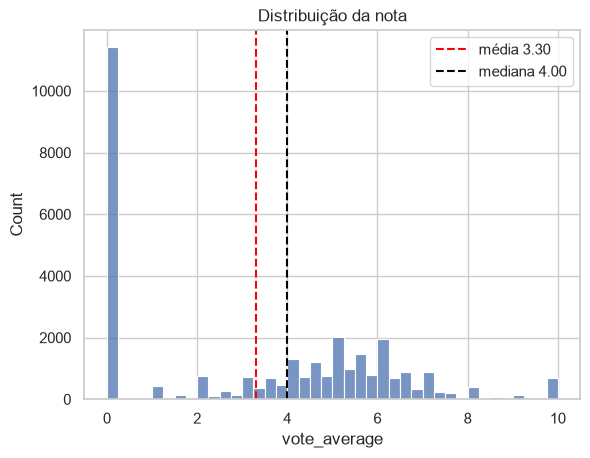

In [16]:
media = round(terror["vote_average"].mean(), 2)
mediana = terror["vote_average"].median()

# o mesmo par, restrito aos filmes que têm pelo menos um voto
com_algum_voto = terror[terror["vote_count"] >= 1]
media_com_voto = round(com_algum_voto["vote_average"].mean(), 2)
mediana_com_voto = round(com_algum_voto["vote_average"].median(), 2)

print("todos         — média:", media, "| mediana:", mediana)
print("com >= 1 voto — média:", media_com_voto, "| mediana:", mediana_com_voto)

sns.histplot(data=terror, x="vote_average", bins=40)
plt.axvline(media, color="red", linestyle="--", label=f"média {media:.2f}")
plt.axvline(mediana, color="black", linestyle="--", label=f"mediana {mediana:.2f}")
plt.title("Distribuição da nota")
plt.legend()
plt.show()

Uma barra enorme em zero — **36% do recorte** — e o resto espremido entre 3
e 8. A média (**3,30**) e a mediana (**4,00**) ficam as duas *abaixo* da
massa dos filmes que de fato têm nota.

Dá para medir o tamanho do estrago: entre os filmes com pelo menos um voto,
a média é **5,17** e a mediana é **5,20**. Na tabela inteira, caem para
3,30 e 4,00.

Essa é a lição de hoje, e ela é mais específica do que parece: **a mediana
é robusta a valores extremos, mas não é robusta a um terço da tabela estar
errada.** Zero aqui não é um outlier — é um valor falso repetido onze mil
vezes, e nem a mediana escapa disso.

### A mesma medida, por grupo

`groupby` separa as linhas por década e aplica o `quantile` em cada grupo.
É o `aggregate()` do R, e já apareceu na aula 2.

In [17]:
terror_votado.groupby("decada")["vote_average"].quantile([0.25, 0.5, 0.75])

decada      
1970    0.25    5.675
        0.50    6.200
        0.75    6.700
1980    0.25    5.400
        0.50    5.900
        0.75    6.400
1990    0.25    5.300
        0.50    5.900
        0.75    6.300
2000    0.25    5.200
        0.50    5.700
        0.75    6.200
2010    0.25    5.100
        0.50    5.600
        0.75    6.200
2020    0.25    5.800
        0.50    6.200
        0.75    6.600
Name: vote_average, dtype: float64

Leia por linha: cada década tem seus três quartis. A mediana vai de 5,70
(anos 2000) a 6,20 (anos 1970 e 2020). O centro praticamente não se moveu
em cinquenta anos — e isso vai importar muito na seção 5.

### SUA VEZ — troque a coluna

Faça a mesma tabela de quartis por década para `runtime`.

```python
terror_votado.groupby("decada")["runtime"].quantile([0.25, 0.5, 0.75])
```

In [18]:
terror_votado.groupby("decada")["runtime"].quantile([0.25, 0.5, 0.75])

decada      
1970    0.25     89.00
        0.50     94.00
        0.75    101.00
1980    0.25     88.00
        0.50     93.00
        0.75     99.00
1990    0.25     88.00
        0.50     95.00
        0.75    103.00
2000    0.25     88.00
        0.50     93.00
        0.75    100.25
2010    0.25     86.00
        0.50     91.00
        0.75     99.00
2020    0.25     88.00
        0.50     94.00
        0.75    102.25
Name: runtime, dtype: float64

A mediana da duração fica entre 91 e 95 minutos em **todas** as décadas.
Um filme de terror com avaliação, bem avaliado, dura cerca de uma hora e
meia hoje como durava em 1970.

### O caso do dinheiro

Bilheteria é onde a assimetria fica mais óbvia, porque os números são
grandes e familiares.

In [19]:
media_receita = round(terror_bilheteria["revenue"].mean())
mediana_receita = round(terror_bilheteria["revenue"].median())

maiores_bilheterias = terror_bilheteria.nlargest(3, "revenue")[["title", "ano", "revenue"]]
tabela = maiores_bilheterias.to_string(index=False)

print("filmes com bilheteria registrada:", n_bilheteria)
print()
print("média:  ", media_receita)
print("mediana:", mediana_receita)
print()
print(tabela)

filmes com bilheteria registrada: 1532

média:   28511951
mediana: 3992334

      title  ano   revenue
         It 2017 701842551
World War Z 2013 531865000
    The Meg 2018 530243742


Média **28,5 milhões**, mediana **4,0 milhões**. *It* (2017) sozinho fez
701,8 milhões — 176 vezes a mediana.

A defesa natural da média é "mas ela inclui todo mundo". Então tire o 1%
maior e veja o que sobra.

In [20]:
corte_topo = terror_bilheteria["revenue"].quantile(0.99)

sem_o_topo = terror_bilheteria[terror_bilheteria["revenue"] < corte_topo]

media_sem_topo = round(sem_o_topo["revenue"].mean())
razao = round(sem_o_topo["revenue"].mean() / terror_bilheteria["revenue"].median(), 1)

print("média sem o 1% maior:", media_sem_topo)
print("mediana:             ", mediana_receita)
print("razão:               ", razao)

média sem o 1% maior: 24556258
mediana:              3992334
razão:                6.2


Ainda **6,2 vezes** a mediana. O problema não era um punhado de outliers:
é a forma da distribuição. Cortar a cauda não conserta a média, só esconde
o quanto ela é frágil.

Os quartis dizem a mesma coisa sem precisar de argumento: 25% dos filmes
com bilheteria faturaram até **199 mil**, e 25% faturaram acima de **28,0
milhões**. Repare que o quartil de cima é 140 vezes o de baixo — e é isso
que a seção 4 vai medir.

---

## 4 · Dispersão: o quanto eles variam  `⏱️ 52–72 min`

Posição diz onde está o centro. Dispersão diz **o quanto os valores se
afastam dele** — e duas variáveis com a mesma média podem ser
completamente diferentes.

| medida | Python | o que ela é |
|---|---|---|
| amplitude | `serie.max() - serie.min()` | a mais frágil de todas |
| variância | `serie.var()` | desvio ao quadrado, em unidade ao quadrado |
| desvio padrão | `serie.std()` | a variância de volta na unidade original |
| IQR | `q75 - q25` | a largura do miolo, com 50% dos dados |
| CV | `std / mean` | dispersão relativa, sem unidade |

Comece pela duração dos filmes.

In [21]:
duracao = terror_votado["runtime"]

minimo = duracao.min()
maximo = duracao.max()
amplitude = maximo - minimo
variancia = round(duracao.var(), 2)
desvio = round(duracao.std(), 2)

print("mínimo:   ", minimo)
print("máximo:   ", maximo)
print("amplitude:", amplitude)
print()
print("variância:", variancia)
print("desvio:   ", desvio)

mínimo:    0
máximo:    272
amplitude: 272

variância: 267.75
desvio:    16.36


Amplitude de **272 minutos**, decidida por exatamente dois filmes: o mais
longo do recorte (272 minutos) e o mais curto — que tem duração **zero**.
Duas linhas em 3.307 mandam na medida inteira.

E repare no de baixo: duração zero não é filme curto, é duração não
registrada. Mesmo depois de exigir 50 votos, sobraram dois filmes sem
`runtime` no recorte. Tirando esses dois, a amplitude cai para 270 — quase
nada muda. O problema não é o número ser grande, é ele ser decidido por
duas linhas.

A variância (**267,75**) não quer dizer nada em minutos, porque é minuto ao
quadrado. O desvio padrão resolve isso voltando à unidade original:
**16,4 minutos**. Um filme bem avaliado dura 93,7 minutos em média e
tipicamente se afasta disso em 16,4 minutos.

### O IQR: o miolo, sem as pontas

O **IQR** (intervalo interquartil) é `q75 - q25`: a largura do bloco
central que contém metade dos filmes. Como ignora as pontas, um valor
extremo não o move.

In [22]:
q25 = terror_votado["runtime"].quantile(0.25)
q75 = terror_votado["runtime"].quantile(0.75)
iqr = q75 - q25

print("q25:", q25, "| q75:", q75)
print("IQR:", iqr)

q25: 87.0 | q75: 100.0
IQR: 13.0


Q25 = 87, Q75 = 100, IQR = **13 minutos**. Metade dos filmes bem avaliados
dura entre 87 e 100 minutos.

A amplitude dizia 272; o IQR diz 13. Os dois números estão certos e
respondem perguntas diferentes: a amplitude responde "qual é o intervalo
total", o IQR responde "onde está a massa".

### SUA VEZ — preencha as lacunas

Calcule o IQR da nota, em `terror_votado`, com a mesma receita.

```python
coluna = terror_votado["vote_average"]

iqr = coluna.quantile(0.75) - coluna.quantile(0.25)

print("IQR:", iqr)
```

In [23]:
coluna = terror_votado["vote_average"]

iqr = coluna.quantile(0.75) - coluna.quantile(0.25)

print("IQR:", iqr)

IQR: 1.0


IQR = **1,00**. Metade dos filmes bem avaliados tem nota dentro de uma
faixa de um ponto. Comparado com a escala de 0 a 10, é uma faixa
estreitíssima — a nota é uma variável muito mais comportada do que o
dinheiro.

### O boxplot

O boxplot desenha o IQR: a caixa vai de q25 a q75, a linha dentro dela é
a mediana, e os bigodes alcançam 1,5 IQR para cada lado. O que sobra vira
ponto isolado.

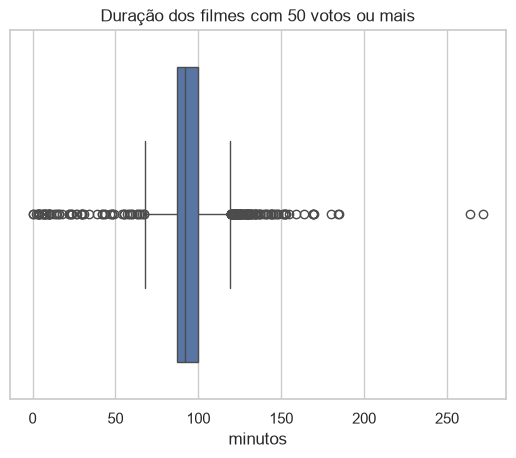

In [24]:
sns.boxplot(data=terror_votado, x="runtime")
plt.title("Duração dos filmes com 50 votos ou mais")
plt.xlabel("minutos")
plt.show()

Caixa estreita e centrada. As bolinhas à direita são filmes longos que a
regra de 1,5 IQR marca como fora do padrão — não porque sejam erros, mas
porque são raros. **Outlier é uma definição, não um fato.**

E tem uma bolinha isolada à esquerda, sozinha, longe de tudo: é um dos
dois filmes com duração zero. O boxplot encontrou a duração não registrada
sem que ninguém tivesse pedido.

Agora o mesmo desenho por década, no conjunto **inteiro**.

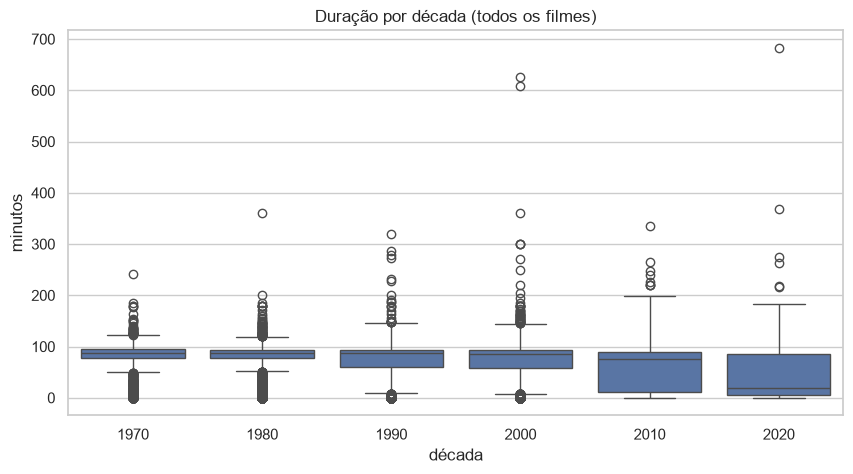

In [25]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=terror, x="decada", y="runtime")
plt.title("Duração por década (todos os filmes)")
plt.xlabel("década")
plt.ylabel("minutos")
plt.show()

As caixas de 2010 e 2020 são enormes e têm uma massa de pontos embaixo.
Aquilo não são filmes curtos: são **curtas-metragens**. 34% da tabela tem
duração de até 40 minutos, com mediana de **7 minutos** — enquanto a
mediana dos longas é 89.

Duas populações na mesma tabela, e o boxplot acabou de mostrar. Guarde a
imagem.

### SUA VEZ — troque a variável

Faça o boxplot de `vote_average` por década, no conjunto `terror`. A
mesma massa de pontos aparece?

```python
sns.boxplot(data=terror, x="decada", y="vote_average")
plt.title("Nota por década")
plt.xlabel("década")
plt.show()
```

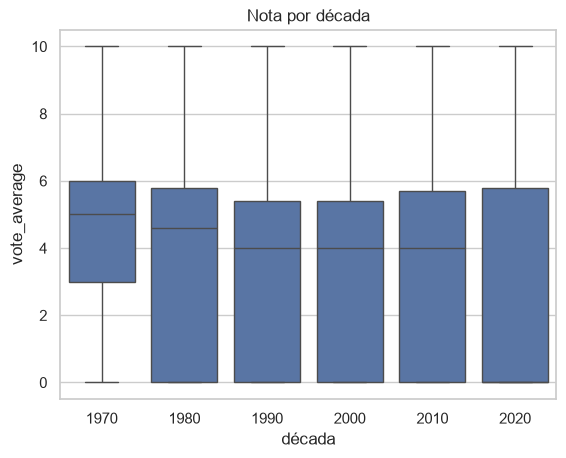

In [26]:
sns.boxplot(data=terror, x="decada", y="vote_average")
plt.title("Nota por década")
plt.xlabel("década")
plt.show()

Aparece — e agora embaixo, na nota zero. Confirma o diagnóstico: a massa
de pontos é feita de filmes sem informação, não de filmes extremos.

### Comparando dispersão entre variáveis: o CV

Um desvio de 16 minutos e um desvio de 0,85 ponto não se comparam — são
unidades diferentes. O **coeficiente de variação** divide o desvio pela
média e devolve um número sem unidade. Aí sim dá para comparar.

Vamos montar uma tabela pequena com uma **lista de tuplas** e construir o
DataFrame a partir dela.

In [27]:
linhas = [
    ("vote_count", terror_votado["vote_count"]),
    ("runtime", terror_votado["runtime"]),
    ("vote_average", terror_votado["vote_average"]),
    ("revenue", terror_bilheteria["revenue"]),
]

dispersao = pd.DataFrame(
    [(nome, serie.mean(), serie.std(), serie.std() / serie.mean())
     for nome, serie in linhas],
    columns=["variavel", "media", "desvio", "cv"],
)

dispersao.round(2).set_index("variavel")

,media,desvio,cv
variavel,,,
vote_count,557.03,1199.54,2.15
runtime,93.65,16.36,0.17
vote_average,5.78,0.85,0.15
revenue,28511951.16,60393398.98,2.12


Os CVs vão de **0,15** (nota) a **2,15** (número de votos) — catorze vezes
de diferença, na mesma base de filmes. A nota é a variável mais previsível
da tabela; votos e dinheiro, as mais imprevisíveis.

Repare também que `revenue` vem de `terror_bilheteria` e as outras três de
`terror_votado`. Sem dizer de qual conjunto cada número saiu, a tabela
seria mentira. **Sempre diga quem entrou na conta** — é literalmente o
assunto da próxima seção.

### opcional / se der tempo — o z-score

O **z-score** diz quantos desvios padrão um valor está acima ou abaixo da
média. Como é a mesma conta para qualquer variável, ele permite comparar o
quanto um filme é extremo em dinheiro e em nota. Não precisa de
biblioteca: é uma subtração e uma divisão.

In [28]:
receita = terror_bilheteria["revenue"]

terror_bilheteria["z_receita"] = (receita - receita.mean()) / receita.std()

grandes = (terror_bilheteria["z_receita"] > 3).sum()
maiores_z = terror_bilheteria.nlargest(3, "z_receita")[["title", "ano", "revenue", "z_receita"]].round(2)
tabela = maiores_z.to_string(index=False)

print("filmes acima de 3 desvios:", grandes)
print()
print(tabela)

filmes acima de 3 desvios: 35

      title  ano   revenue  z_receita
         It 2017 701842551      11.15
World War Z 2013 531865000       8.33
    The Meg 2018 530243742       8.31


**35** filmes passam de 3 desvios, e *It* está a **11,15** — um evento que
a média e o desvio padrão não descrevem, e que o `describe()` também não.

Um z-score de 11 é o tipo de número que faz você desconfiar do estimador,
não do filme. É exatamente aí que a próxima seção começa.

---

## 5 · A virada: a dispersão que você vê  `⏱️ 72–90 min`

Até aqui tudo funcionou. Agora a pergunta que a análise exploratória obriga
a fazer antes de qualquer conclusão.

*O terror ficou mais extremo com o tempo?*

A medida de dispersão responde. Repare que `com_algum_voto` já está
definido desde a seção 3 — variável criada uma vez serve a aula inteira,
não precisa recriar.

In [29]:
sd_por_decada = com_algum_voto.groupby("decada")["vote_average"].std()

sd_por_decada.round(2)

decada
1970    1.35
1980    1.48
1990    1.68
2000    1.72
2010    1.85
2020    2.16
Name: vote_average, dtype: float64

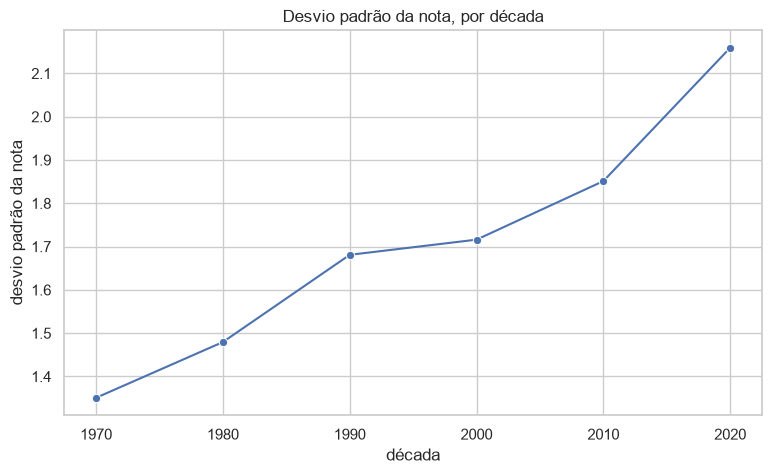

In [30]:
plt.figure(figsize=(9, 5))
sns.lineplot(x=sd_por_decada.index, y=sd_por_decada.values, marker="o")
plt.title("Desvio padrão da nota, por década")
plt.xlabel("década")
plt.ylabel("desvio padrão da nota")
plt.show()

Uma subida limpa: **1,35** nos anos 1970, **2,16** nos anos 2020. Sessenta
por cento de aumento, monotônico, em cinco décadas.

A história se escreve sozinha: *"as notas de terror ficaram mais
polarizadas"*. É uma frase bonita, publicável, e provavelmente falsa.

Antes de escrever, olhe de novo para a composição da tabela.

In [31]:
poucos = (terror["vote_count"] < 10).sum()
proporcao = round(100 * poucos / n_terror, 1)

print("filmes com menos de 10 votos:", poucos)
print("total em terror:             ", n_terror)
print("proporção:                   ", proporcao, "%")

filmes com menos de 10 votos: 23490
total em terror:              31431
proporção:                    74.7 %


Quase três em cada quatro filmes de `terror` têm menos de 10 votos. Um
filme com dois votos entra na conta com nota 10 ou com nota 3, e cada um
desses casos empurra o desvio padrão para cima — porque desvio padrão
mede distância, e não existe distância maior do que a que vem de um
número instável.

A pergunta muda de forma:

> Quanto do crescimento é polarização de verdade, e quanto é filme sem
> avaliação entrando na conta?

Para responder, olhe como a **composição** da tabela muda de década para
década: qual fração de cada década tem avaliação suficiente.

A média de uma coluna de Verdadeiro/Falso é a proporção de Verdadeiros —
o mesmo truque do filtro booleano da aula 2.

In [32]:
terror["bem_avaliado"] = terror["vote_count"] >= 50

(100 * terror.groupby("decada")["bem_avaliado"].mean()).round(1)

decada
1970    13.5
1980    14.4
1990    11.8
2000    13.0
2010    10.1
2020     5.8
Name: bem_avaliado, dtype: float64

**13,5%** nos anos 1970, **5,8%** nos anos 2020. A fração de filmes com
avaliação suficiente caiu para menos da metade em cinco décadas.

É isso que faz a curva subir. Não é o terror que mudou — é a tabela.

### SUA VEZ — preencha as lacunas

Exija um mínimo de 50 votos e refaça a mesma conta. É a mesma linha de
código, com um número diferente.

```python
bem_votados = terror[terror["vote_count"] >= 50]

bem_votados.groupby("decada")["vote_average"].std().round(2)
```

In [33]:
bem_votados = terror[terror["vote_count"] >= 50]

bem_votados.groupby("decada")["vote_average"].std().round(2)

decada
1970    0.80
1980    0.76
1990    0.84
2000    0.82
2010    0.88
2020    0.64
Name: vote_average, dtype: float64

**0,80 / 0,76 / 0,84 / 0,82 / 0,88 / 0,64** — sem subida. Com uma exigência
mínima de 50 votos, a "polarização crescente" simplesmente não está lá.

Talvez 50 seja um corte arbitrário. Então não escolha um: desenhe todos.
Um `for` sobre a lista de cortes monta uma tabela longa, e o `hue` do
seaborn transforma cada corte numa linha.

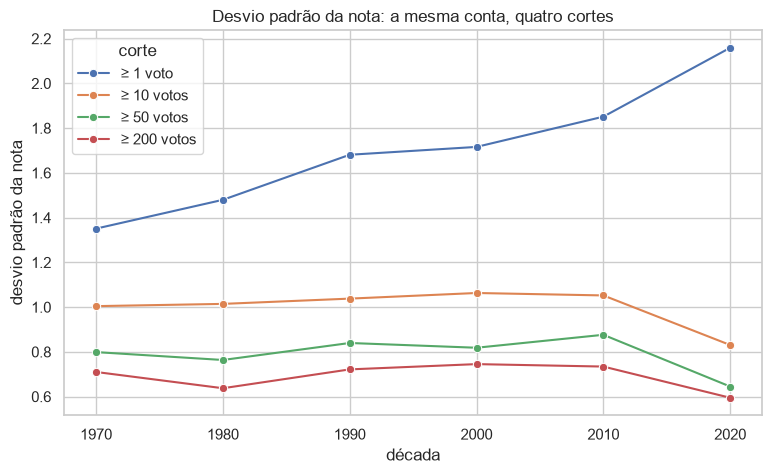

In [34]:
cortes = [1, 10, 50, 200]

partes = []
rotulos = []

for corte in cortes:
    sub = terror[terror["vote_count"] >= corte]
    sd = sub.groupby("decada")["vote_average"].std()
    rotulo = f"≥ {corte} voto" if corte == 1 else f"≥ {corte} votos"
    rotulos.append(rotulo)
    partes.append(pd.DataFrame({"decada": sd.index, "sd": sd.values, "corte": rotulo}))

curvas = pd.concat(partes)

plt.figure(figsize=(9, 5))
sns.lineplot(data=curvas, x="decada", y="sd", hue="corte", hue_order=rotulos, marker="o")
plt.title("Desvio padrão da nota: a mesma conta, quatro cortes")
plt.xlabel("década")
plt.ylabel("desvio padrão da nota")
plt.show()

Quatro curvas, mesma conta, mesmo dado. A única que sobe é a que aceita
filmes com um único voto. De 10 votos para cima, todas ficam retas — e as
três terminam **mais baixas** do que começaram.

O `describe()` da seção 1 diria que a conclusão depende de um detalhe
técnico. A curva mostra que não.

Falta eliminar a última dúvida: e se o problema for o desvio padrão, que é
sensível a valores extremos? Então refaça com o **IQR**, que não é.

In [35]:
for corte in cortes:
    sub = terror[terror["vote_count"] >= corte]
    faixa = sub.groupby("decada")["vote_average"]
    iqr = faixa.quantile(0.75) - faixa.quantile(0.25)
    valores = "  ".join(f"{v:.2f}" for v in iqr)
    print(f"≥ {corte:>3} votos:", valores)

≥   1 votos: 1.70  1.70  2.00  2.10  2.20  2.10
≥  10 votos: 1.20  1.40  1.35  1.50  1.50  1.00
≥  50 votos: 1.03  1.00  1.00  1.00  1.10  0.80
≥ 200 votos: 1.10  0.80  0.92  0.90  0.90  0.72


O IQR conta exatamente a mesma história que o desvio padrão. Então não é
culpa do estimador: **é o corte.**

E tem mais uma variável para testar, uma que não tem nada a ver com voto:
a duração. Se o problema for o corte, ela deve sofrer do mesmo mal.

In [36]:
for nome, conjunto in [("terror", terror), ("terror_votado", terror_votado)]:
    faixa = conjunto.groupby("decada")["runtime"]
    iqr = faixa.quantile(0.75) - faixa.quantile(0.25)
    valores = "  ".join(f"{v:.0f}" for v in iqr)
    print(f"{nome:<15}", valores)

terror          18  17  34  34  79  79
terror_votado   12  11  15  12  13  14


No conjunto inteiro, o IQR da duração vai de 18 a 79 minutos — parece que
os filmes ficaram muito mais variados em tamanho. Restringindo aos bem
avaliados, fica entre 11 e 15 minutos, sem tendência nenhuma em cinco
décadas.

Não foram os filmes que mudaram. As **curtas-metragens** — 34% da tabela,
mediana de 7 minutos — foram entrando na base e alargando a caixa. É
literalmente a armadilha da aula 2, quando cada linha era
música-em-playlist e não música.

Sobra uma última pergunta: se a dispersão é artefato, e o **centro**?

In [37]:
terror_votado.groupby("decada")["vote_average"].agg(["median", "std"]).round(2)

,median,std
decada,,
1970,6.2,0.80
1980,5.9,0.76
1990,5.9,0.84
2000,5.7,0.82
2010,5.6,0.88
2020,6.2,0.64


Nem a mediana nem o desvio padrão se movem de forma sistemática. Cinco
décadas, mediana entre 5,60 e 6,20, desvio entre 0,64 e 0,88.

O que **não** quer dizer que nada aconteceu no terror em cinquenta anos.
Quer dizer que este resumo, nesta tabela, não mostra o que aconteceu.

Uma peça do quebra-cabeça fica de fora: a queda do desvio nos anos 2020
aparece em todos os cortes, mas são só três anos (2020–2022) e 328
filmes com 50 votos ou mais. Não vamos explicar isso hoje. Fica anotado.

---

## 6 · De volta à pergunta  `⏱️ 90–95 min`

> *Um filme de terror típico existe?*

**Na tabela crua, não.** A média de votos é 63 e a mediana é 2. A média de
bilheteria é 28,5 milhões e a mediana é 4,0 milhões; mesmo tirando o 1%
maior, a média continua sendo 6,2 vezes a mediana. O "filme típico" que a
média descreve não existe em lugar nenhum: três em cada quatro filmes da
tabela têm menos de 10 votos.

**Num recorte, quase.** Entre os filmes com 50 votos ou mais, o resumo é
estável: nota mediana entre 5,60 e 6,20 e desvio entre 0,64 e 0,88, em
cinco décadas.

E o caminho até essas duas frases foi sempre o mesmo:

**olhar o dado → resumir a posição → resumir a dispersão → perguntar quem
entrou na conta.**

O último passo é o que hoje separou um achado de um artefato. A leitura
ingênua dizia que o terror ficou mais polarizado em cinquenta anos. A
leitura correta é que a tabela ficou mais cheia de filmes que quase
ninguém avaliou: a proporção de filmes com 50 votos ou mais caiu de 13,5%
nos anos 1970 para 5,8% nos anos 2020.

O número não estava errado. Estava respondendo outra pergunta.

---

## 7 · Para onde isso leva  `⏱️ 95–100 min`

Todas as medidas de hoje têm nome e sobrenome no pandas, e o R faz igual:

| medida | Python | equivalente em R |
|---|---|---|
| média, mediana | `serie.mean()`, `serie.median()` | `mean()`, `median()` |
| quartis e percentis | `serie.quantile([.25, .5, .75])` | `quantile()` |
| desvio padrão, variância | `serie.std()`, `serie.var()` | `sd()`, `var()` |
| resumo completo | `serie.describe()` | `summary()` |
| agrupado | `groupby(...).agg([...])` | `aggregate()` |
| contagem por valor | `serie.value_counts()` | `table()` |

Um detalhe que morde: `serie.std()` do pandas divide por **n − 1**, igual
ao `sd()` do R. Mas `np.std()` do NumPy divide por **n**. Com 3.307 filmes
a diferença aparece na quarta decimal e ninguém nota; num vetor de cinco
números ela muda a segunda casa. Se um dia um número não bater com o do
R, olhe aqui primeiro.

E a lição que não está em nenhuma tabela de tradução: a parte difícil
nunca foi calcular. `describe()` responde em uma linha — e responde a
pergunta errada quando 74% da tabela não tem a informação que você quer
medir. Nenhuma função do pandas sabe disso por você.

### Para brincar depois

Nada disso é para entregar. Se quiser continuar:

- `budget` tem o mesmo problema de `revenue`? Só 1.062 dos 1.532 filmes
  com bilheteria têm orçamento. O que isso faz com uma razão
  receita/orçamento?
- A queda do desvio nos anos 2020 reaparece em todos os cortes. É real ou
  é a década incompleta?
- Troque o boxplot de duração por um de `vote_count`. Por que ele fica
  ilegível?
- Calcule o z-score da bilheteria de `budget` e compare a lista de extremos
  com a de `revenue`. Os mesmos filmes aparecem?
- Refaça a curva da seção 5 com `popularity` no lugar de `vote_average`. A
  conclusão se sustenta?

Este notebook fica com você. Ele roda de novo a qualquer momento, do zero,
em qualquer máquina com navegador.